# RainNext24h exploratory data analysis

Workbook ID 21. Explores the RainNext24h labels (ID 22) and the Open-Meteo variables available at the forecast origin *t*, to choose features for ID 23.

**Data scope.** Labels: `gold/ml_labels/rain_next24h_labels_v2.parquet` (label implementation `rain_next24h_v0.2.1`, which fixes the float-sum error that labelled exact 1.0 mm windows No in v1; 1 mm over `(t, t+24h]`, Open-Meteo, UTC splits with boundary purge; see `docs/rain-label.md`). Variables: Silver Open-Meteo hourly, 8 research points, 2016–2025. This is gridded reanalysis rainfall, not gauge observations, so findings describe a retrospective experiment.

**Leakage rule.** Every table or chart used to *choose* features uses the **train split (2016–2023) only**. Class balance is shown for all splits because it describes labels, not features. The test split (2025) is not inspected beyond its size and positive rate.

**Reproduce.** `make notebook-setup` once, then `make notebook-run` with MinIO running and the Silver/Gold data present (see `docs/progress.md`). The computations live in `scripts/rain_eda.py` (tested in `tests/test_rain_eda.py`); this notebook only displays them.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rain_eda as eda
from export_rain_labels import labels_keys, read_open_meteo_silver
from load_gold_observations import BUCKET_GOLD, get_minio_client

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Validated reference palette (dataviz skill): light surface, recessive chrome
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES_1 = "#2a78d6"  # single-series marks
DIVERGING_POS, DIVERGING_NEG = "#2a78d6", "#e34948"  # blue <-> red poles
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "figure.dpi": 110, "axes.axisbelow": True,
})

## Load labels and origin variables

In [2]:
client = get_minio_client()
labels = eda.load_labels(client, BUCKET_GOLD, labels_keys()[0])
hourly = read_open_meteo_silver(
    client, 2016, 2025,
    columns=["location_code", "timestamp_utc", "precipitation_mm", "temperature_c", "dew_point_c",
             "humidity_percent", "pressure_hpa", "cloud_cover_percent", "wind_speed_ms",
             "solar_radiation_wm2"],
)
df = eda.add_origin_variables(labels, hourly)
print(f"label rows {len(labels):,}; hourly rows {len(hourly):,}; usable labelled origins {len(eda.usable(df)):,}")

label rows 701,376; hourly rows 701,376; usable labelled origins 700,800


## 1. Class balance by split

The 1 mm threshold gives a near-balanced target in every split, so accuracy alone is not misleading and an always-Yes baseline scores about 50%.

,rows,positive_rate
split,,
train,560832,0.516
validation,70080,0.501
test,69888,0.497


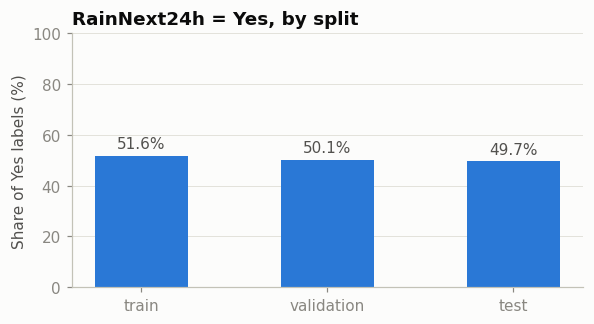

In [3]:
balance = eda.class_balance(df)
display(balance)
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(balance.index, balance["positive_rate"] * 100, color=SERIES_1, width=0.5)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in balance["positive_rate"] * 100], color=INK_2, padding=3)
ax.set_ylim(0, 100); ax.set_ylabel("Share of Yes labels (%)")
ax.set_title("RainNext24h = Yes, by split")
ax.grid(axis="x", visible=False)
plt.show()

## 2. Seasonality and location (train only)

Share of Yes labels by research point and calendar month of the origin in Vietnam local time (UTC+7), the same month as the `month_local` feature in ID 23. (Until 2026-10-22 this table used the UTC month; the two differ only for origins 17:00–23:00 UTC on a month's last day.)

month,1,2,3,4,5,6,7,8,9,10,11,12
location_code,,,,,,,,,,,,
HAN,37.300,35.300,42.000,43.000,55.400,57.500,66.400,79.500,70.400,45.600,30.300,23.600
HBI,32.100,28.400,37.200,39.300,57.500,60.500,68.400,78.300,73.700,48.800,28.100,22.100
HPH,26.800,30.700,36.000,41.700,57.400,63.800,72.400,82.900,73.200,44.900,32.100,21.500
LCA,75.000,75.200,78.000,73.400,75.800,78.100,76.900,79.500,75.400,57.300,54.000,53.200
NBI,33.600,28.900,32.800,32.800,50.500,49.800,60.400,75.000,77.300,52.100,34.100,23.700
PTO,34.700,28.500,37.600,40.600,54.900,59.100,67.500,76.000,70.600,47.100,31.300,22.200
TNG,41.700,38.000,55.600,49.900,59.700,71.200,71.900,80.800,66.500,44.500,31.000,26.200
TUQ,35.900,30.900,41.600,46.100,57.900,66.200,72.400,76.900,71.800,44.100,31.200,20.000


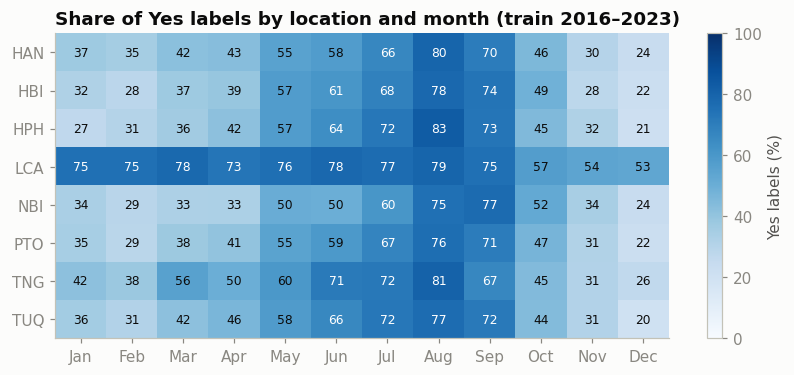

In [4]:
matrix = eda.month_location_matrix(df) * 100
display(matrix.round(1))
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(matrix.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(12), [pd.Timestamp(2024, m, 1).strftime("%b") for m in matrix.columns])
ax.set_yticks(range(len(matrix.index)), matrix.index)
ax.grid(False)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else INK)
fig.colorbar(im, ax=ax, label="Yes labels (%)")
ax.set_title("Share of Yes labels by location and month (train 2016–2023)")
plt.show()

## 3. Time of day (train only)

Share of Yes labels by origin hour in Vietnam local time (UTC+7). A strong cycle would make the hour a useful feature.

local_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
yes_pct,51.800,51.900,52.000,52.000,52.000,51.800,51.800,51.600,51.600,51.500,...,51.600,51.600,51.400,51.300,51.400,51.300,51.400,51.500,51.600,51.700


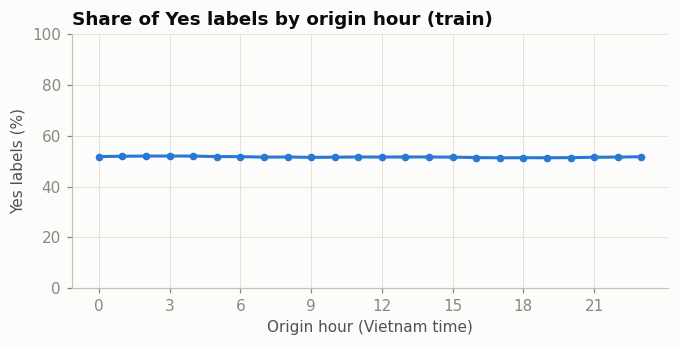

In [5]:
tr = eda.usable(df)
tr = tr[tr["split"] == "train"].assign(local_hour=lambda x: (x["origin_utc"].dt.hour + 7) % 24)
by_hour = tr.groupby("local_hour")["rain_next24h"].apply(lambda s: s.astype(float).mean() * 100)
display(by_hour.to_frame("yes_pct").T.round(1))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_hour.index, by_hour.values, color=SERIES_1, linewidth=2, marker="o", markersize=4)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Origin hour (Vietnam time)"); ax.set_ylabel("Yes labels (%)")
ax.set_ylim(0, 100)  # full scale: the hourly cycle is under 1 percentage point
ax.set_title("Share of Yes labels by origin hour (train)")
plt.show()

## 4. Target rainfall and data completeness

Distribution of the next-24-hour rain total (train) and the share of missing values among usable rows. Trailing 24-hour variables are missing only for the first 24 hours of 2016.

In [6]:
display(eda.target_rain_distribution(df).to_frame("next_24h_rain_mm_train"))
display(eda.missingness(df, eda.ORIGIN_VARIABLES + eda.DERIVED_VARIABLES).to_frame())

,next_24h_rain_mm_train
share_zero,0.278
mean,6.140
q25,0.000
q50,1.100
q75,7.200
q90,18.400
q99,55.200


,missing_share
temperature_c,0.000
dew_point_c,0.000
humidity_percent,0.000
pressure_hpa,0.000
cloud_cover_percent,0.000
wind_speed_ms,0.000
solar_radiation_wm2,0.000
precipitation_mm,0.000
dew_point_depression_c,0.000
rain_past_24h_mm,0.000


## 5. Which variables at *t* separate Yes from No (train only)

Standardized mean difference (SMD = difference of class means / pooled standard deviation). |SMD| ≥ 0.5 is a medium separation. This screens raw variables; it does not select the final feature set.

,mean_yes,mean_no,smd
variable,,,
dew_point_c,22.457,18.076,0.807
rain_past_24h_mm,10.188,1.818,0.752
humidity_percent,86.413,76.910,0.749
pressure_hpa,"1,005.019","1,010.299",-0.722
dew_point_depression_c,2.573,4.556,-0.707
cloud_cover_percent,84.232,62.116,0.662
precipitation_mm,0.473,0.023,0.478
temperature_c,25.030,22.632,0.441
pressure_change_24h_hpa,0.291,-0.316,0.243


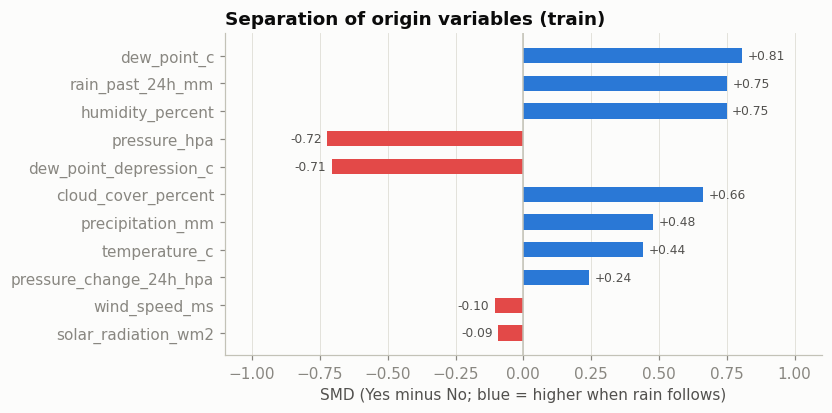

In [7]:
sep = eda.variable_separation(df, eda.ORIGIN_VARIABLES + eda.DERIVED_VARIABLES)
display(sep)
fig, ax = plt.subplots(figsize=(7, 3.8))
order = sep.index[::-1]
vals = sep.loc[order, "smd"]
ax.barh(order, vals, color=[DIVERGING_POS if v >= 0 else DIVERGING_NEG for v in vals], height=0.55)
ax.axvline(0, color="#c3c2b7", linewidth=1)
for y, v in enumerate(vals):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK_2)
lim = float(np.ceil(vals.abs().max() * 10) / 10) + 0.2
ax.set_xlim(-lim, lim)
ax.set_xlabel("SMD (Yes minus No; blue = higher when rain follows)")
ax.set_title("Separation of origin variables (train)")
ax.grid(axis="y", visible=False)
plt.show()

## 5b. Correlation between variables (train only)

Spearman rank correlation between the origin variables (train split). Pairs with |ρ| ≥ 0.8 carry largely the same information: a tree can use either, and its importance is then shared between them. This answers the workbook's "tương quan các biến" item; it is a description, not a feature filter.

,variable_a,variable_b,correlation
0,humidity_percent,dew_point_depression_c,-0.998
1,temperature_c,dew_point_c,0.872
2,dew_point_c,pressure_hpa,-0.803


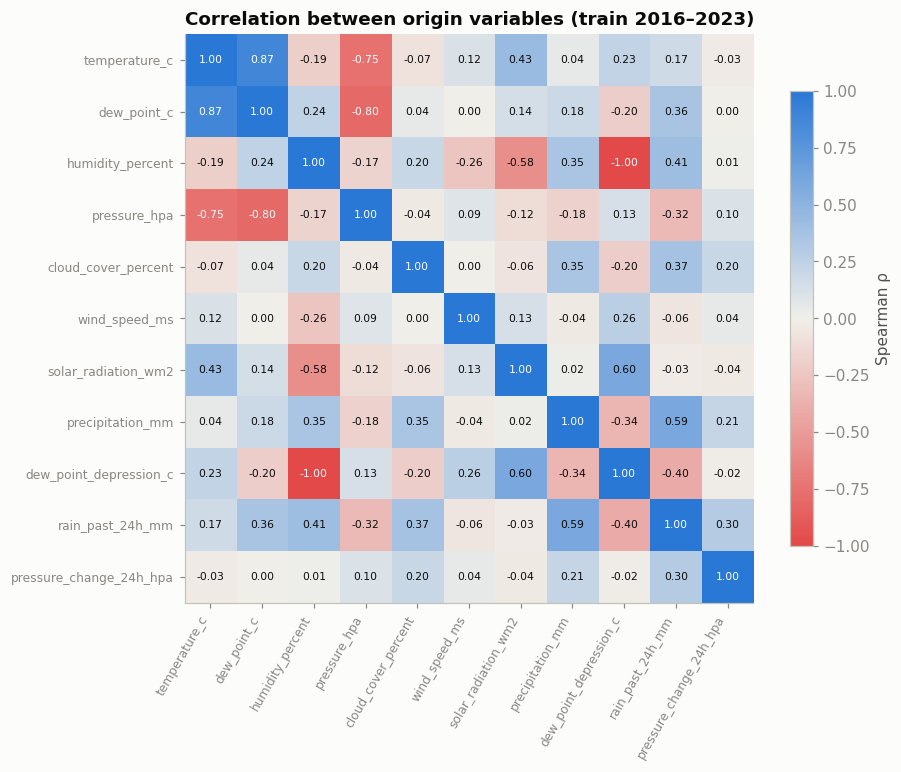

In [8]:
from matplotlib.colors import LinearSegmentedColormap

corr_cols = eda.ORIGIN_VARIABLES + eda.DERIVED_VARIABLES
corr = eda.variable_correlation(df, corr_cols)
pairs = eda.strong_pairs(corr, 0.8)
display(pairs)
cmap = LinearSegmentedColormap.from_list("div", [DIVERGING_NEG, "#f0efea", DIVERGING_POS])
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.7 else INK)
fig.colorbar(im, ax=ax, label="Spearman ρ", shrink=0.8)
ax.set_title("Correlation between origin variables (train 2016–2023)")
plt.tight_layout(); plt.show()

## 6. Rain probability by binned predictor (train only)

Three candidate predictors, each in its own panel (one y-scale per panel).

rain_past_24h_mm,"[0.0, 0.1)","[0.1, 1.0)","[1.0, 5.0)","[5.0, 10.0)","[10.0, 25.0)","[25.0, 50.0)","[50.0, 1000.0)"
rows,155951,115121,118776,59539,76851,27004,7406
positive_pct,17.161,38.368,62.183,78.369,86.798,91.138,92.398


humidity_percent,"[0, 50)","[50, 60)","[60, 70)","[70, 80)","[80, 90)","[90, 95)","[95, 101)"
rows,12344,27893,64466,107982,145998,93870,108279
positive_pct,5.476,13.799,28.018,43.785,56.296,64.732,70.923


dew_point_depression_c,"[0, 1)","[1, 2)","[2, 4)","[4, 6)","[6, 8)","[8, 12)","[12, 40)"
rows,110278,103768,144681,96406,56599,40277,8807
positive_pct,70.328,64.026,54.751,43.273,30.520,16.975,6.438


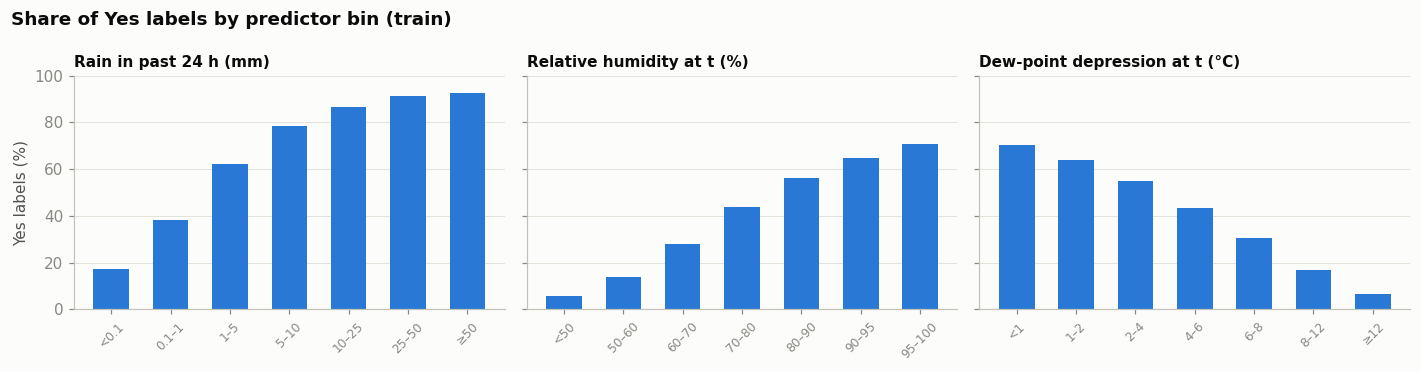

In [9]:
panels = [
    ("rain_past_24h_mm", [0, 0.1, 1, 5, 10, 25, 50, 1000], "Rain in past 24 h (mm)",
     ["<0.1", "0.1–1", "1–5", "5–10", "10–25", "25–50", "≥50"]),
    ("humidity_percent", [0, 50, 60, 70, 80, 90, 95, 101], "Relative humidity at t (%)",
     ["<50", "50–60", "60–70", "70–80", "80–90", "90–95", "95–100"]),
    ("dew_point_depression_c", [0, 1, 2, 4, 6, 8, 12, 40], "Dew-point depression at t (°C)",
     ["<1", "1–2", "2–4", "4–6", "6–8", "8–12", "≥12"]),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (col, bins, label, names) in zip(axes, panels):
    rates = eda.binned_positive_rate(df, col, bins)
    assert len(rates) == len(names), col
    ax.bar(names, rates["positive_rate"] * 100, color=SERIES_1, width=0.6)
    ax.set_title(label, fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(axis="x", visible=False); ax.set_ylim(0, 100)
    display(rates.assign(positive_pct=lambda r: r["positive_rate"] * 100).drop(columns="positive_rate").T)
axes[0].set_ylabel("Yes labels (%)")
fig.suptitle("Share of Yes labels by predictor bin (train)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.show()

## 7. Key numbers for the report

Computed, not typed, so they always match the data above.

In [10]:
wettest_month = matrix.mean().idxmax(); driest_month = matrix.mean().idxmin()
summary = {
    "usable_labelled_origins": len(eda.usable(df)),
    "train_yes_pct": round(balance.loc["train", "positive_rate"] * 100, 2),
    "validation_yes_pct": round(balance.loc["validation", "positive_rate"] * 100, 2),
    "test_yes_pct": round(balance.loc["test", "positive_rate"] * 100, 2),
    "wettest_month_mean_yes_pct": (int(wettest_month), round(matrix.mean().max(), 1)),
    "driest_month_mean_yes_pct": (int(driest_month), round(matrix.mean().min(), 1)),
    "wettest_location_train": matrix.mean(axis=1).idxmax(),
    "hourly_yes_pct_range_train": (round(by_hour.min(), 1), round(by_hour.max(), 1)),
    "top3_variables_by_abs_smd": list(sep.index[:3]),
    "pairs_with_abs_spearman_ge_0_8": [
        (r.variable_a, r.variable_b, round(r.correlation, 2)) for r in pairs.itertuples()
    ],
}
summary

{'usable_labelled_origins': 700800,
 'train_yes_pct': 51.64,
 'validation_yes_pct': 50.1,
 'test_yes_pct': 49.65,
 'wettest_month_mean_yes_pct': (8, 78.6),
 'driest_month_mean_yes_pct': (12, 26.5),
 'wettest_location_train': 'LCA',
 'hourly_yes_pct_range_train': (51.3, 52.0),
 'top3_variables_by_abs_smd': ['dew_point_c',
  'rain_past_24h_mm',
  'humidity_percent'],
 'pairs_with_abs_spearman_ge_0_8': [('humidity_percent',
   'dew_point_depression_c',
   -1.0),
  ('temperature_c', 'dew_point_c', 0.87),
  ('dew_point_c', 'pressure_hpa', -0.8)]}

## Implications for feature engineering (ID 23)

- Keep month and location: the seasonal and between-location differences in §2 are large. This section first suggested month as sin/cos; ID 23 kept an integer `month_local` (1–12) because CART splits on thresholds and can isolate any run of months, while sin/cos mainly helps linear models (recorded 2026-10-22).
- Strongly correlated pairs (§5b) overlap: keep them for CART, but read their importances together.
- The hour of day changes the Yes share by less than 1 percentage point (§3): include it only as a cheap optional feature; do not expect it to matter.
- Prefer the variables at the top of §5 and their trailing changes (3 h / 24 h); use dew-point depression rather than temperature and dew point separately if it ranks higher.
- All trailing windows must end at *t* and be computed per location on a gap-checked grid (as in `scripts/rain_eda.py`).
- No threshold, transform, or feature choice may use validation or test statistics.